# Sesión 2 — Taller práctico: qué gráfico corresponde a cada pregunta (CONECTA, proyecto A: Retención)

**Grupo:** 9  
**Nombre:** Mario Daniel Enrique Perez Jimenez  
**Cédula:** 1152456361  
**Código de estudiante:** 202610093727

**Curso:** Visualización de Datos y Gerencia de la Información  
**Sesión:** 2 de 9  
**Tipo:** Notebook práctico

## Instrucciones de entrega

- Equipos de 3 personas. Entreguen este notebook **ejecutado de inicio a fin** como
  `DATAVIZ_sesion_2_proyecto_A_grupo_Y.ipynb` en el plazo acordado en clase.
- Completen las celdas `# TODO` y escriban en las celdas **Su respuesta**.
- Pueden consultar el notebook guiado, pero escriban su propio código. Pueden apoyarse en un asistente de IA para
  concentrarse en lo importante y en las decisiones; declaren al final para qué lo usaron.

## Problemática de negocio

CONECTA S.A. es un operador de telecomunicaciones en Bogotá con dos líneas, **Hogar** (internet fijo) y **Móvil**
(pospago y prepago), con datos sintéticos del curso. La Gerencia de Retención lleva al comité de diciembre una
propuesta de campaña contra las cancelaciones para el primer trimestre de 2027. La ficha de la S1 dejó el destinatario
(el comité directivo), la decisión (en qué zonas concentrar la campaña y cuánto invertir) y la pregunta: **¿dónde se
cancela más?** Le falta el indicador. Como analistas, deben:

1. Definir el indicador y ver dónde y quién cancela más.
2. Hacer un gráfico por tipo de dato: cantidades, distribuciones, tiempo, incertidumbre y relaciones.
3. Dejar en una tabla lo que llevan a la S4, donde se escribirá la recomendación al comité (el SCQA): cada gráfico de
   hoy es una pieza de esa recomendación.

Los datos todavía no se revisan (S3): trabajen con las 19 localidades con nombre oficial. El diccionario de datos
está en `datos/diccionario_conecta.md`; los segmentos (Hogar, Móvil pospago y Móvil prepago) se explican allí.

## Preparación del entorno

In [1]:
import pathlib

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# El notebook busca datos/ e imagenes/ en su carpeta (o en la de arriba, si está en solucionario/).
BASE = pathlib.Path(".") if pathlib.Path("datos").exists() else pathlib.Path("..")
DATOS, IMAGENES = BASE / "datos", BASE / "imagenes"
IMAGENES.mkdir(exist_ok=True)
# Lo que produce el taller se guarda en salidas/, junto al notebook que se ejecuta (el del estudiante en su carpeta;
# el del solucionario, en solucionario/salidas/): así el solucionario no deja respuestas en la carpeta del estudiante.
SALIDAS = pathlib.Path("salidas")
SALIDAS.mkdir(exist_ok=True)

PALETA = {"principal": "#0F766E", "principal_claro": "#4E9F96", "marino": "#1F2A44", "secundario": "#5B6475",
          "neutro": "#8A93A3", "fondo": "#F3F5F9", "acento": "#B85C0A", "texto": "#1F2937"}
plt.rcParams.update({
    "font.family": "Calibri", "font.size": 11, "axes.edgecolor": PALETA["secundario"],
    "axes.labelcolor": PALETA["texto"], "xtick.color": PALETA["secundario"], "ytick.color": PALETA["secundario"],
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 150, "savefig.dpi": 150,
    "savefig.bbox": "tight"})
# Con Calibri, matplotlib no dibuja bien los tamaños enteros 8 y 9 (se usan 8.5, 9.5 o más) ni el texto a 110 ppp: figure.dpi = 150.


def miles(n, redondeo=0):
    """Entero con espacio de miles; redondeo=-3 redondea a miles."""
    return f"{round(n, redondeo):,.0f}".replace(",", " ")


def decimal(x, d=1):
    return f"{x:.{d}f}".replace(".", ",")


def titulo(fig, texto, subtitulo, y=1.04):
    fig.text(0.01, y, texto, fontsize=15, fontweight="bold", color=PALETA["texto"], ha="left")
    fig.text(0.01, y - 0.055, subtitulo, fontsize=11, color=PALETA["secundario"], ha="left")


def fuente(fig, texto):
    fig.text(0.01, -0.04, texto, fontsize=8.5, color=PALETA["secundario"], ha="left")


def guardar(fig, nombre):
    """Guarda la figura en imagenes/ (la presentación usa estos archivos) y la muestra."""
    fig.savefig(IMAGENES / nombre)
    plt.show()


def limpiar_ejes(ax, x=True, y=False):
    if x:
        ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
    if y:
        ax.set_yticks([])
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)

def intervalo_proporcion(exitos, n, z=1.96):
    """Proporción con su intervalo del 95 % (OpenIntro, §5.2, p. 204) y la condición de éxito-fracaso (p. 205)."""
    p = exitos / n
    se = np.sqrt(p * (1 - p) / n)
    cumple = (exitos >= 10) & ((n - exitos) >= 10)
    return pd.DataFrame({"p": p, "inferior": p - z * se, "superior": p + z * se, "n": n, "cumple": cumple})

In [2]:
FUENTE_CONECTA = "Fuente: CONECTA S.A., datos sintéticos del curso (nov. 2025 – oct. 2026)."
h = pd.read_csv(DATOS / "conecta_clientes_mes.csv", dtype={"mes": str})
upz = gpd.read_file(DATOS / "upz.geojson")
# Segmento del cliente (ver el diccionario): Hogar, Móvil pospago o Móvil prepago.
h["segmento"] = np.where(h["linea"] == "Hogar", "Hogar", np.where(h["modalidad"] == "Prepago", "Móvil prepago", "Móvil pospago"))
o = h[h["localidad"].isin(set(upz["localidad"]))]      # filas con el nombre oficial de la localidad
variantes_localidad = h["localidad"].nunique()
print(f"{miles(len(h))} filas; {miles(len(o))} con nombre oficial de localidad")
print(f"La columna localidad tiene {variantes_localidad} valores distintos para {upz['localidad'].nunique()} localidades oficiales")

354 693 filas; 347 595 con nombre oficial de localidad
La columna localidad tiene 38 valores distintos para 19 localidades oficiales


## Tarea 1 — El indicador: dónde y quién cancela más

La S1 dejó la pregunta sin indicador. Defínanlo con su fórmula y calcúlenlo para toda la base (`tasa_general`, en %).
Luego, en una figura de dos paneles con barras **desde cero, ordenadas** y con los valores (Wilke, 2019, pp. 45–58):
la tasa por localidad (`tasa_localidad`, **dónde**) y la tasa por segmento (`tasa_segmento`, **quién**).

*Consulten en la presentación:* diapositiva 7, «Razón precio/ingreso» (sección «El indicador»); diapositiva 12, «Cantidades» (sección «El directorio de gráficos»).

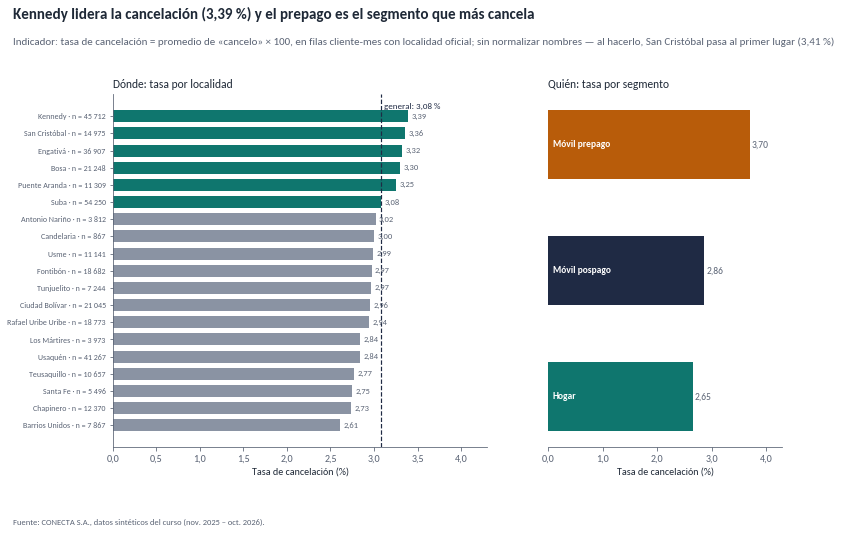

tasa_general = 3,08 % (oficial); 3,09 % con toda la base


2 201 clientes vuelven a aparecer tras su primer mes con cancelo = 1


localidad,BARRIOS UNIDOS,CHAPINERO,SANTA FE,TEUSAQUILLO,USAQUEN,LOS MARTIRES,RAFAEL URIBE URIBE,CIUDAD BOLIVAR,TUNJUELITO,FONTIBON,USME,CANDELARIA,ANTONIO NARIÑO,SUBA,PUENTE ARANDA,BOSA,ENGATIVA,SAN CRISTOBAL,KENNEDY
tasa_localidad_%,2.61,2.73,2.75,2.77,2.84,2.84,2.94,2.96,2.97,2.97,2.99,3.0,3.02,3.08,3.25,3.3,3.32,3.36,3.39


In [3]:
tasa_general = 100 * o["cancelo"].mean()     # cada fila es un cliente-mes
tasa_localidad = (100 * o.groupby("localidad")["cancelo"].mean()).sort_values()
tasa_segmento = (100 * o.groupby("segmento")["cancelo"].mean()).sort_values()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 6.5), gridspec_kw={"width_ratios": [1.6, 1]})

# Dónde: las 19 localidades, barras horizontales ordenadas con la general marcada.
colores_loc = [PALETA["principal"] if v >= tasa_general else PALETA["neutro"] for v in tasa_localidad]
a1.barh(tasa_localidad.index, tasa_localidad, color=colores_loc, height=0.7)
for y, v in enumerate(tasa_localidad):
    a1.text(v + 0.04, y, decimal(v, 2), va="center", fontsize=8.5, color=PALETA["secundario"])
a1.axvline(tasa_general, color=PALETA["marino"], linestyle="--", linewidth=1.2)
a1.text(tasa_general + 0.03, len(tasa_localidad) - 0.6, f"general: {decimal(tasa_general, 2)} %",
        fontsize=9, color=PALETA["marino"])
a1.set_xlim(0, 4.3); a1.set_xlabel("Tasa de cancelación (%)"); a1.set_ylabel("")
a1.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: decimal(v, 1)))
NOMBRES19 = {"ANTONIO NARIÑO": "Antonio Nariño", "BARRIOS UNIDOS": "Barrios Unidos", "BOSA": "Bosa",
             "CANDELARIA": "Candelaria", "CHAPINERO": "Chapinero", "CIUDAD BOLIVAR": "Ciudad Bolívar",
             "ENGATIVA": "Engativá", "FONTIBON": "Fontibón", "KENNEDY": "Kennedy",
             "LOS MARTIRES": "Los Mártires", "PUENTE ARANDA": "Puente Aranda",
             "RAFAEL URIBE URIBE": "Rafael Uribe Uribe", "SAN CRISTOBAL": "San Cristóbal",
             "SANTA FE": "Santa Fe", "SUBA": "Suba", "TEUSAQUILLO": "Teusaquillo",
             "TUNJUELITO": "Tunjuelito", "USAQUEN": "Usaquén", "USME": "Usme"}
n_loc = o.groupby("localidad").size()
a1.set_yticks(range(len(tasa_localidad)))
a1.set_yticklabels([f"{NOMBRES19[l]} · n = {miles(n_loc[l])}" for l in tasa_localidad.index], fontsize=8)
a1.set_title("Dónde: tasa por localidad", loc="left", fontsize=11.5, color=PALETA["texto"])

# Quién: los tres segmentos, desde cero, con el nombre dentro de la barra y el valor afuera.
COLOR_SEG = {"Móvil prepago": PALETA["acento"], "Móvil pospago": PALETA["marino"], "Hogar": PALETA["principal"]}
colores_seg = [COLOR_SEG[s] for s in tasa_segmento.index]  # mismos colores que en T2
a2.barh(tasa_segmento.index, tasa_segmento, color=colores_seg, height=0.55)
for y, (s, v) in enumerate(tasa_segmento.items()):
    a2.text(0.08, y, s, va="center", ha="left", fontsize=9.5, color="white", fontweight="bold")
    a2.text(v + 0.04, y, decimal(v, 2), va="center", fontsize=9.5, color=PALETA["secundario"])
a2.set_yticks([])
a2.set_xlim(0, 4.3); a2.set_xlabel("Tasa de cancelación (%)")
a2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: decimal(v, 1)))
a2.spines["left"].set_visible(False)
a2.set_title("Quién: tasa por segmento", loc="left", fontsize=11.5, color=PALETA["texto"])

titulo(fig, f"Kennedy lidera la cancelación ({decimal(tasa_localidad['KENNEDY'], 2)} %) y el prepago es el segmento que más cancela",
       "Indicador: tasa de cancelación = promedio de «cancelo» × 100, en filas cliente-mes con localidad oficial; "
       "sin normalizar nombres — al hacerlo, San Cristóbal pasa al primer lugar (3,41 %)")
fuente(fig, FUENTE_CONECTA)
guardar(fig, "t1_tasa_localidad_segmento.png")

print(f"tasa_general = {decimal(tasa_general, 2)} % (oficial); {decimal(100 * h['cancelo'].mean(), 2)} % con toda la base")
ultimo_mes = h.groupby("cliente_id")["mes"].max()
primer_cancelo = h.loc[h["cancelo"] == 1].groupby("cliente_id")["mes"].min()
n_reap = int((ultimo_mes.loc[primer_cancelo.index] > primer_cancelo).sum())
print(f"{miles(n_reap)} clientes vuelven a aparecer tras su primer mes con cancelo = 1")
display(pd.DataFrame({"tasa_localidad_%": tasa_localidad.round(2)}).T)

**Escriban el indicador con su fórmula y digan qué muestran los dos paneles: ¿dónde y quién cancela más?**

*Consulten en la presentación:* diapositiva 7, «Razón precio/ingreso» (sección «El indicador»); diapositiva 12, «Cantidades» (sección «El directorio de gráficos»).

**Su respuesta:** El indicador es la **tasa de cancelación**: `100 × promedio de cancelo` sobre las filas cliente-mes; la general es **3,08 %** sobre las filas con nombre oficial de localidad (la base del taller; con toda la base da 3,09 %). **Dónde:** Kennedy (3,39 %), San Cristóbal (3,36 %), Engativá (3,32 %), Bosa (3,30 %) y Puente Aranda (3,25 %) están por encima de la general — la figura muestra el n de cada localidad; Suba queda justo en la general (3,08 %) y las más bajas son Barrios Unidos (2,61 %) y Chapinero (2,73 %). **Quién:** el **Móvil prepago** cancela más (3,70 %), seguido del Móvil pospago (2,86 %) y el Hogar (2,65 %): el prepago es ~1,4 veces el hogar (y ~2,4 veces si se descuentan los «cambio de plan», que son migración y no baja). Ojo: `cancelo` mezcla bajas con cambios de plan — el 22,7 % de las cancelaciones son «cambio de plan» y 2 201 clientes reaparecen tras «cancelar» (impreso en la celda); la distinción fina queda para la S3/S4.


## Tarea 2 — Distribuciones

1. Histograma de `ingreso_mensual_cop` (lo que paga el cliente; ver el diccionario), **un color por segmento**.
2. Distribución de `antiguedad_meses` según `cancelo`: un histograma para las filas con cancelación y otro para las
   demás, cada uno en porcentaje de su grupo (los dos grupos tienen tamaños muy distintos).

*Consulten en la presentación:* diapositiva 15, «Distribuciones» (sección «El directorio de gráficos»); diapositiva 50, «Los segmentos de clientes» (sección «Incertidumbre y la primera lista»).

< 6 meses: 14,4 % de quienes cancelan vs 9,7 % de quienes no (oficiales); 14,5 % con toda la base; mediana de antigüedad: 31 vs 33 meses


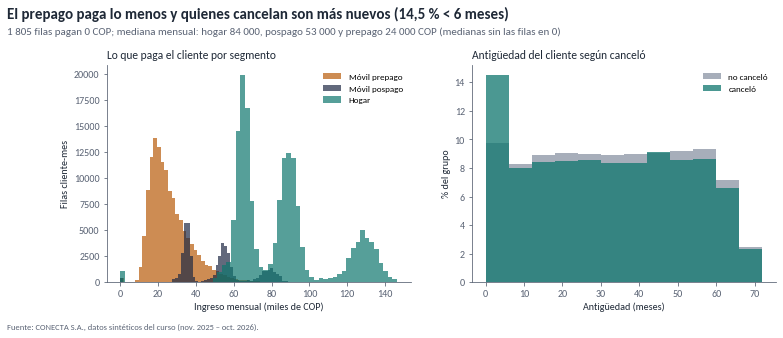

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))

# Lo que paga el cliente por segmento (miles de COP).
for seg, color in (("Móvil prepago", PALETA["acento"]), ("Móvil pospago", PALETA["marino"]), ("Hogar", PALETA["principal"])):
    a1.hist(h.loc[h["segmento"] == seg, "ingreso_mensual_cop"] / 1000, bins=60, alpha=0.7,
            label=seg, color=color)
a1.set_xlabel("Ingreso mensual (miles de COP)"); a1.set_ylabel("Filas cliente-mes")
a1.set_title("Lo que paga el cliente por segmento", loc="left", fontsize=11.5, color=PALETA["texto"])
a1.legend(frameon=False, fontsize=9)

ceros = int((h["ingreso_mensual_cop"] == 0).sum())     # filas en 0 (¿altas gratis, errores?)
tarifa_segmento = h[h["ingreso_mensual_cop"] > 0].groupby("segmento")["ingreso_mensual_cop"].median()

# Antigüedad según cancelo, cada grupo en % de sí mismo.
bins = range(0, 78, 6)                                   # intervalos de seis meses
for valor, color, rot in ((0, PALETA["neutro"], "no canceló"), (1, PALETA["principal"], "canceló")):
    x = h.loc[h["cancelo"] == valor, "antiguedad_meses"]
    a2.hist(x, bins=bins, weights=np.full(len(x), 100 / len(x)), alpha=0.75, label=rot, color=color)
a2.set_xlabel("Antigüedad (meses)"); a2.set_ylabel("% del grupo")
a2.set_title("Antigüedad del cliente según canceló", loc="left", fontsize=11.5, color=PALETA["texto"])
a2.legend(frameon=False, fontsize=9)

nuevos = 100 * h.groupby("cancelo")["antiguedad_meses"].apply(lambda s: (s < 6).mean())
nuevos_o = 100 * o.groupby("cancelo")["antiguedad_meses"].apply(lambda s: (s < 6).mean())
med_c = h.loc[h["cancelo"] == 1, "antiguedad_meses"].median()
med_n = h.loc[h["cancelo"] == 0, "antiguedad_meses"].median()
print(f"< 6 meses: {decimal(nuevos_o[1])} % de quienes cancelan vs {decimal(nuevos_o[0])} % de quienes no "
      f"(oficiales); {decimal(nuevos[1])} % con toda la base; mediana de antigüedad: {med_c:.0f} vs {med_n:.0f} meses")
titulo(fig, f"El prepago paga lo menos y quienes cancelan son más nuevos ({decimal(nuevos[1])} % < 6 meses)",
       f"{miles(ceros)} filas pagan 0 COP; mediana mensual: hogar {miles(tarifa_segmento['Hogar'], -3)}, pospago {miles(tarifa_segmento['Móvil pospago'], -3)} y prepago {miles(tarifa_segmento['Móvil prepago'], -3)} COP (medianas sin las filas en 0)")
fuente(fig, FUENTE_CONECTA)
guardar(fig, "t2_distribuciones.png")
plt.show()

**¿Qué observan en los dos histogramas? ¿Qué preguntarían antes de usar lo que paga el cliente?**

*Consulten en la presentación:* diapositiva 15, «Distribuciones» (sección «El directorio de gráficos»); diapositiva 50, «Los segmentos de clientes» (sección «Incertidumbre y la primera lista»).

**Su respuesta:** En lo que paga el cliente se ven tres niveles separados: hogar mediana ≈ 84 mil COP, pospago ≈ 53 mil y prepago ≈ 24 mil, con **1 805 filas (0,5 %) en 0 COP**, la mayoría de hogar. En la antigüedad, los que cancelan están más concentrados en los primeros meses: el **14,4 % de quienes cancelan tienen menos de 6 meses** frente al 9,7 % de los que no (oficiales; 14,5 % con toda la base, mediana 31 vs. 33 meses — todo impreso en la celda). Antes de usar `ingreso_mensual_cop` preguntaríamos: ¿por qué hay filas en 0 (¿mes de alta gratis, exoneraciones o errores de registro?) y qué significa en prepago un mes con recarga cero: ¿cliente inactivo o abandono silencioso?


## Tarea 3 — Tiempo en múltiplos pequeños

**Para qué:** ver si hay localidades que cancelan más **todo el año** o solo en algunos meses.

Si se dibujan las 19 localidades como 19 líneas en un mismo gráfico, se cruzan y no se lee ninguna. La solución son
los **múltiplos pequeños**: muchos gráficos pequeños iguales, uno por localidad, puestos en una cuadrícula y con la
**misma escala**, para que el ojo compare de un panel a otro (Wilke, 2019, pp. 255 y 258–259). En matplotlib, una
cuadrícula de 2 × 3 paneles con `plt.subplots(2, 3, sharey=True)` (`sharey=True` da la misma escala vertical).

1. **La serie:** la tasa de cancelación de cada localidad en cada mes (`serie`: filas = meses; columnas =
   localidades).
2. **Qué localidades:** seis, porque caben en la cuadrícula de 2 × 3. Escojan las seis con **más clientes**
   (`cliente_id` distintos por localidad): son las que más pesan para CONECTA y las de tasa más estable.
3. **La referencia:** en cada panel, una línea gris con el **promedio simple de las 19 localidades** en cada mes
   (el promedio de las 19 tasas, sin ponderar por clientes), rotulada. Sin ella no se sabe si una localidad está alta
   o baja.
4. **El resumen:** cuenten cuántos de los 12 meses está cada localidad por encima de ese promedio (`meses_sobre`),
   pónganlo en el título de cada panel y usen el resultado en el título del gráfico.

*Consulten en la presentación:* diapositiva 22, «Múltiplos pequeños» (sección «El directorio de gráficos»).

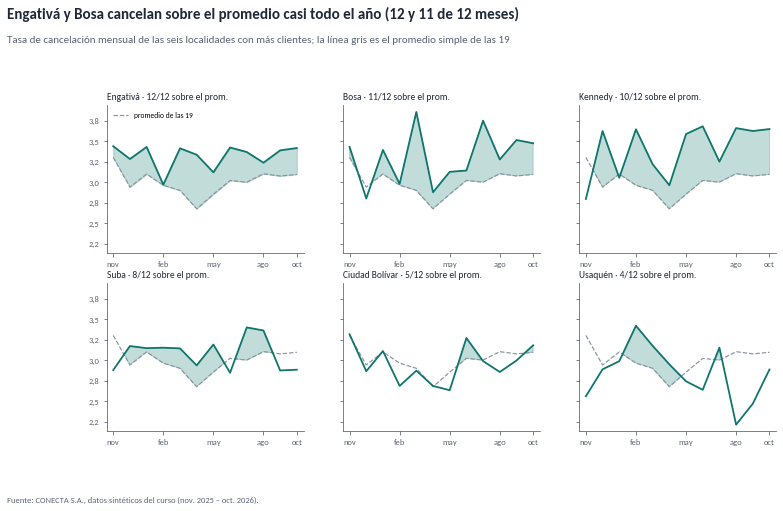

In [5]:
serie = 100 * o.groupby(["mes", "localidad"])["cancelo"].mean().unstack()   # filas: mes; columnas: localidad
promedio = serie.mean(axis=1)           # promedio simple de las 19 localidades (no ponderado)
grandes = o.groupby("localidad")["cliente_id"].nunique().nlargest(6).index
meses_sobre = serie[grandes].gt(promedio, axis=0).sum().sort_values(ascending=False)   # meses arriba, de más a menos

x = np.arange(len(serie))
fig, ejes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)   # la misma escala en todos los paneles
for ax, loc in zip(ejes.flat, meses_sobre.index):           # paneles ordenados por meses arriba
    n_sobre = int(meses_sobre[loc])
    ax.plot(x, serie[loc], color=PALETA["principal"], linewidth=1.8, zorder=3)
    ax.plot(x, promedio, color=PALETA["neutro"], linewidth=1.2, linestyle="--", zorder=2, label="promedio de las 19")
    ax.fill_between(x, serie[loc], promedio, where=serie[loc] > promedio, interpolate=True,
                    color=PALETA["principal"], alpha=0.25)   # resalta los meses arriba
    ax.set_title(f"{NOMBRES19[loc]} · {n_sobre}/12 sobre el prom.", loc="left",
                 fontsize=9.5, color=PALETA["texto"])
    ax.set_xlim(-0.4, 11.4)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: decimal(v, 1)))
    ax.set_xticks([0, 3, 6, 9, 11]); ax.set_xticklabels(["nov", "feb", "may", "ago", "oct"], fontsize=8.5)
    ax.tick_params(axis="y", labelsize=8.5)

ejes.flat[0].legend(frameon=False, fontsize=7.5, loc="upper left")  # rótulo de la línea de referencia

titulo(fig, f"Engativá y Bosa cancelan sobre el promedio casi todo el año ({int(meses_sobre.iloc[0])} y {int(meses_sobre.iloc[1])} de 12 meses)",
       "Tasa de cancelación mensual de las seis localidades con más clientes; la línea gris es el promedio simple de las 19",
       y=1.08)
fuente(fig, FUENTE_CONECTA)
guardar(fig, "t3_multiplos_pequenos.png")
plt.show()

**¿Hay localidades que cancelan más todo el año o solo en algunos meses? ¿Qué gana el lector con los múltiplos pequeños frente a un solo gráfico con todas las líneas?**

*Consulten en la presentación:* diapositiva 22, «Múltiplos pequeños» (sección «El directorio de gráficos»).

**Su respuesta:** De las seis localidades con más clientes, **Engativá (12 de 12) y Bosa (11 de 12) están sobre el promedio casi todo el año**, Kennedy 10 de 12 y Suba 8 de 12: son altas de forma estructural, no por un mes malo; Usaquén y Ciudad Bolívar solo se pasan 4–5 meses (San Cristóbal también acumula 10 de 12, pero no está entre las seis con más clientes). Con los múltiplos pequeños el lector compara cada localidad contra la misma referencia y la misma escala, algo imposible en un solo gráfico con 19 líneas cruzadas; además el conteo de meses sobre el promedio resume el patrón de cada panel.


## Tarea 4 — Incertidumbre: una muestra aleatoria

Con toda la base, la tasa de cada localidad es la real: no hay error de muestreo. Para ver qué hace un intervalo de
confianza, trabajen como si solo tuvieran una muestra:

1. Tomen una **muestra aleatoria de 30 000 filas** cliente-mes: `o.sample(30_000, random_state=2026)` (menos del
   10 % de la base). Así se cumple la condición de independencia.
2. Calculen la tasa de cada localidad en la muestra con su intervalo del 95 % (`intervalo_proporcion`, Diez et al.,
   2019, §5.2) y agreguen la **tasa real** de toda la base (`real`).
3. Grafiquen los intervalos con la tasa real marcada, cuenten cuántos la contienen (`contienen`) y marquen las
   localidades que no cumplen la condición de éxito-fracaso.

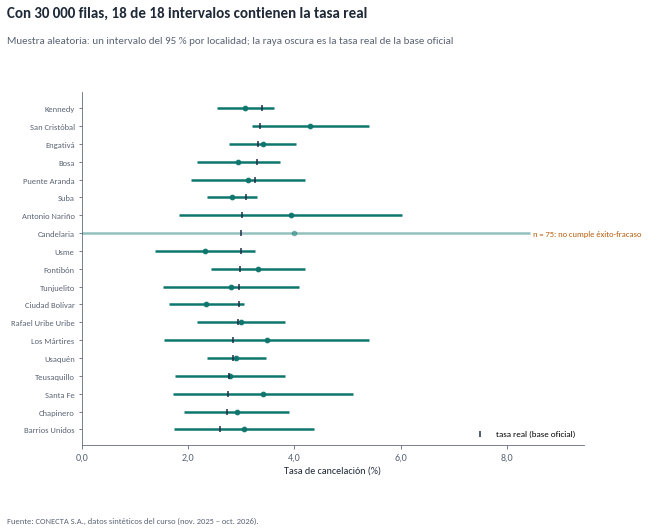

                       p  inferior  superior     n  cumple  real  contiene
localidad                                                                 
ANTONIO NARIÑO      3.93      1.83      6.02   331    True  3.02      True
BARRIOS UNIDOS      3.05      1.74      4.37   655    True  2.61      True
BOSA                2.95      2.16      3.73  1799    True  3.30      True
CANDELARIA          4.00     -0.43      8.43    75   False  3.00      True
CHAPINERO           2.91      1.92      3.91  1099    True  2.73      True
CIUDAD BOLIVAR      2.35      1.64      3.06  1747    True  2.96      True
ENGATIVA            3.41      2.78      4.04  3198    True  3.32      True
FONTIBON            3.31      2.44      4.19  1599    True  2.97      True
KENNEDY             3.08      2.54      3.61  4000    True  3.39      True
LOS MARTIRES        3.48      1.54      5.41   345    True  2.84      True
PUENTE ARANDA       3.13      2.06      4.20  1022    True  3.25      True
RAFAEL URIBE URIBE  3.00 

In [6]:
muestra = o.sample(30_000, random_state=2026)
conteo = muestra.groupby("localidad")["cancelo"].agg(["sum", "size"])
intervalos = intervalo_proporcion(conteo["sum"], conteo["size"])
intervalos["real"] = o.groupby("localidad")["cancelo"].mean()          # toda la base
intervalos["contiene"] = (intervalos["inferior"] <= intervalos["real"]) & (intervalos["real"] <= intervalos["superior"])
contienen = int(intervalos.loc[intervalos["cumple"], "contiene"].sum())

fig, ax = plt.subplots(figsize=(9, 6.5))   # un intervalo por localidad y la tasa real marcada
orden = intervalos.sort_values("real")
for y, (loc, fila) in enumerate(orden.iterrows()):
    color = PALETA["principal"] if fila["contiene"] else PALETA["acento"]
    alpha = 1 if fila["cumple"] else 0.45
    ax.hlines(y, 100 * fila["inferior"], 100 * fila["superior"], color=color, linewidth=2.5, alpha=alpha)
    ax.scatter(100 * fila["p"], y, color=color, s=22, zorder=3, alpha=alpha)
    ax.scatter(100 * fila["real"], y, color=PALETA["marino"], s=34, marker="|", zorder=4)
    if not fila["cumple"]:
        ax.text(100 * fila["superior"] + 0.06, y, f"n = {miles(fila['n'])}: no cumple éxito-fracaso",
                va="center", fontsize=8.5, color=PALETA["acento"])
ax.set_yticks(range(len(orden))); ax.set_yticklabels([NOMBRES19[l] for l in orden.index], fontsize=8.5)
ax.set_xlim(0, 100 * max(intervalos["superior"]) * 1.12)
ax.set_xlabel("Tasa de cancelación (%)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: decimal(v, 1)))
ax.scatter([], [], color=PALETA["marino"], s=34, marker="|", label="tasa real (base oficial)")
ax.legend(frameon=False, fontsize=9, loc="lower right")
titulo(fig, f"Con 30 000 filas, {contienen} de {int(intervalos['cumple'].sum())} intervalos contienen la tasa real",
       "Muestra aleatoria: un intervalo del 95 % por localidad; la raya oscura es la tasa real de la base oficial")
fuente(fig, FUENTE_CONECTA)
guardar(fig, "t4_intervalos.png")
plt.show()

print(intervalos.assign(p=100 * intervalos["p"], inferior=100 * intervalos["inferior"],
                        superior=100 * intervalos["superior"], real=100 * intervalos["real"])
          .round(2).to_string())

**¿Qué muestra la comparación entre los intervalos de la muestra y la tasa real? ¿Qué le dirían al comité sobre las localidades que no cumplen la condición?**

*Consulten en la presentación:* diapositiva 41, «Intervalo de confianza de una proporción» (sección «Incertidumbre y la primera lista»).

**Su respuesta:** Con la muestra de 30 000 filas, **los 18 intervalos que cumplen la condición de éxito-fracaso contienen la tasa real** de su localidad: con esa n la estimación es precisa. La única que no cumple es **Candelaria**, con muy pocos clientes en la muestra: al comité le diríamos que su tasa puntual no es concluyente, que se tome con cautela o se combine con meses o UPZ vecinas antes de decidir sobre ella. Advertencias: la muestra es de filas cliente-mes (≈ 9,7 filas por cliente, no estrictamente independientes — el error agrupado por cliente da prácticamente igual, así que el 18/18 se mantiene) e incluye 1 765 duplicados cliente-mes; además la base aún no está limpia, pendiente de la S3.


## Tarea 5 — Relaciones: ¿qué acompaña a la cancelación?

`cancelo` solo vale 0 o 1, así que una dispersión directa no sirve (dos líneas de puntos superpuestos). En una
figura de dos paneles:

1. **Localidades:** la tasa de cada localidad (`tasa_localidad`, Tarea 1) frente a su porcentaje de filas prepago
   (`prepago_localidad`), con la correlación (`r_prepago`) en el título del panel.
2. **Quejas:** la tasa según el número de quejas del mes (0, 1, 2, 3 o más), con su intervalo. Muestren también las
   quejas medias por segmento (`quejas_segmento`), para compararlas con la tasa por segmento de la Tarea 1.

*Consulten en la presentación:* diapositiva 24, «Relaciones x–y y puntos superpuestos» (sección «El directorio de gráficos»).

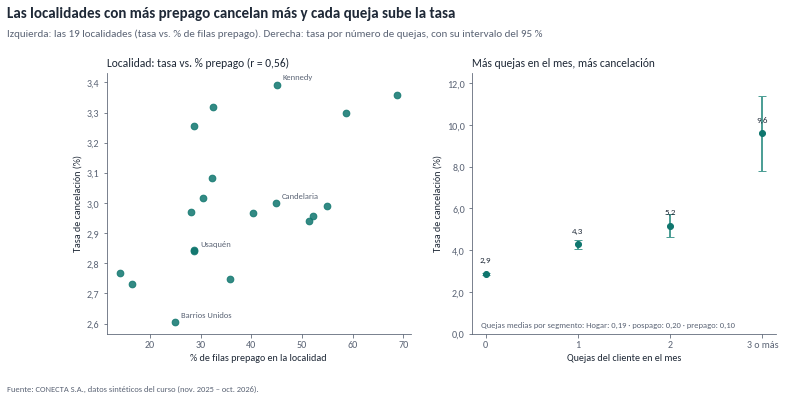

Quejas medias por segmento (también dentro de la figura):
segmento
Hogar            0.192
Móvil pospago    0.203
Móvil prepago    0.104


In [7]:
prepago_localidad = 100 * o.groupby("localidad")["modalidad"].apply(lambda s: (s == "Prepago").mean())
r_prepago = np.corrcoef(prepago_localidad, tasa_localidad.loc[prepago_localidad.index])[0, 1]
por_quejas = h.assign(quejas=h["quejas_mes"].clip(upper=3)).groupby("quejas")["cancelo"].agg(["sum", "size"])
tasa_quejas = intervalo_proporcion(por_quejas["sum"], por_quejas["size"])
quejas_segmento = h.groupby("segmento")["quejas_mes"].mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8))

# Localidades: más prepago, más cancelación.
a1.scatter(prepago_localidad, tasa_localidad.loc[prepago_localidad.index],
           s=45, color=PALETA["principal"], alpha=0.85, zorder=3)
for loc in ["KENNEDY", "BARRIOS UNIDOS", "USAQUEN", "CANDELARIA"]:
    a1.annotate(NOMBRES19[loc], (prepago_localidad[loc], tasa_localidad[loc]),
                textcoords="offset points", xytext=(6, 5), fontsize=8.5, color=PALETA["secundario"])
a1.set_xlabel("% de filas prepago en la localidad"); a1.set_ylabel("Tasa de cancelación (%)")
a1.set_title(f"Localidad: tasa vs. % prepago (r = {decimal(r_prepago, 2)})", loc="left",
             fontsize=11.5, color=PALETA["texto"])

# Quejas del mes: la tasa crece con las quejas.
xq = np.arange(len(tasa_quejas))
a2.errorbar(xq, 100 * tasa_quejas["p"],
            yerr=[100 * (tasa_quejas["p"] - tasa_quejas["inferior"]), 100 * (tasa_quejas["superior"] - tasa_quejas["p"])],
            fmt="o", color=PALETA["principal"], ecolor=PALETA["principal_claro"], elinewidth=2, capsize=4, zorder=3)
for i, v in enumerate(100 * tasa_quejas["p"]):
    a2.text(i, v + 0.55, decimal(v, 1), ha="center", fontsize=9, color=PALETA["texto"])
a2.set_xticks(xq); a2.set_xticklabels(["0", "1", "2", "3 o más"])
a2.set_xlabel("Quejas del cliente en el mes"); a2.set_ylabel("Tasa de cancelación (%)")
a2.set_ylim(0, 12.5)
a2.set_title("Más quejas en el mes, más cancelación", loc="left", fontsize=11.5, color=PALETA["texto"])
a2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: decimal(v, 1)))
a1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: decimal(v, 1)))
txt_q = " · ".join(f"{s.replace('Móvil ', '')}: {decimal(v, 2)}" for s, v in quejas_segmento.items())
a2.text(0.03, 0.02, f"Quejas medias por segmento: {txt_q}", transform=a2.transAxes,
        fontsize=8.5, va="bottom", color=PALETA["secundario"])

titulo(fig, "Las localidades con más prepago cancelan más y cada queja sube la tasa",
       "Izquierda: las 19 localidades (tasa vs. % de filas prepago). Derecha: tasa por número de quejas, con su intervalo del 95 %")
fuente(fig, FUENTE_CONECTA)
guardar(fig, "t5_relaciones.png")
plt.show()

print("Quejas medias por segmento (también dentro de la figura):")
print(quejas_segmento.round(3).to_string())

**Geografía (ya hecho).** Ejecuten la celda sin modificarla: es el mapa de puntos de una muestra de clientes, con los
que cancelaron resaltados. Las coordenadas raras (nulas o fuera de Bogotá) se filtran; la S3 las corrige. Construir
mapas es tema de la S5: hoy solo hay que leerlo.

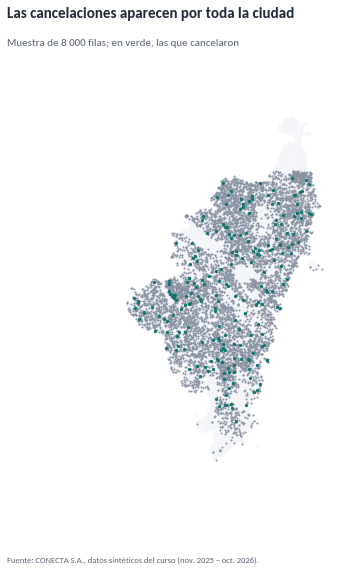

In [8]:
# Ejecute esta celda sin modificarla y observe el resultado.
muestra = h.dropna(subset=["latitud"]).query("latitud > 0").sample(8000, random_state=1)
fig, ax = plt.subplots(figsize=(6, 7))
upz.plot(ax=ax, color=PALETA["fondo"], edgecolor="white", linewidth=0.4)
ax.scatter(muestra["longitud"], muestra["latitud"], s=1, color=PALETA["neutro"])
cancelan = muestra[muestra["cancelo"] == 1]
ax.scatter(cancelan["longitud"], cancelan["latitud"], s=5, color=PALETA["principal"])
ax.set_axis_off()
titulo(fig, "Las cancelaciones aparecen por toda la ciudad", "Muestra de 8 000 filas; en verde, las que cancelaron")
fuente(fig, FUENTE_CONECTA)
plt.show()

**¿Qué acompaña a la cancelación y qué queda por verificar? ¿Qué muestra el mapa y qué no?**

*Consulten en la presentación:* diapositiva 24, «Relaciones x–y y puntos superpuestos» (sección «El directorio de gráficos»); diapositiva 33, «Geografía» (sección «El directorio de gráficos»).

**Su respuesta:** Acompañan a la cancelación el **perfil prepago de la localidad** (r = 0,56 entre % de filas prepago y tasa, una correlación entre localidades — ecológica — que no prueba que el prepago sea quien cancela), las **quejas del mes** (la tasa crece de 2,9 % con 0 quejas a 9,6 % con 3 o más, mostrada en la figura con las medias por segmento: hogar 0,19, pospago 0,20, prepago 0,10) y la **baja antigüedad**. Queda por verificar si el prepago cancela más en todas partes o solo en algunas localidades, y por qué el prepago reporta *menos* quejas medias pese a cancelar más: ¿se queja menos o se va sin quejarse? El mapa muestra cancelaciones repartidas por toda la ciudad, sin un foco geográfico único; lo que no muestra es la tasa por zona, que exige agregar.


## Preguntas de interpretación

**1. La columna localidad tiene 38 valores distintos y el taller usó solo las filas con alguno de los 19 nombres oficiales. ¿Qué riesgo tiene esa decisión para las tasas por localidad?**

**Su respuesta:** Usar solo las filas con los 19 nombres oficiales **deja fuera ~7 100 filas (≈ 2 % de la base)** y el riesgo no es menor: al normalizar tildes y espacios, **San Cristóbal queda primera (3,41 %) y Suba pasa a estar sobre la general (3,10 %)**, porque las grafías alternativas traen tasas distintas a las oficiales («Suba» 4,19 % en 1 098 filas frente a SUBA 3,08 %; «San Cristobal» 5,90 % en 305). Las tasas por localidad de la Tarea 1 son entonces una lectura sin limpiar: el orden del «dónde» puede moverse cuando la S3 reasigne esas filas, así que hay que tomarlas como provisionales.


## Interpretación final para el negocio: lo que llevamos a la S4

En la S4 el equipo escribirá la recomendación al comité en orden SCQA (situación, complicación, pregunta y
respuesta). Redacten un párrafo de 6 a 10 oraciones, para la Gerencia de Retención, con lo que mostraron sus
gráficos: es lo que llevan a la S4. Cubran, con sus cifras:

- **la situación:** cuánto se cancela al mes y dónde (localidades);
- **quién cancela:** el segmento y la relación con el prepago de cada localidad;
- **qué acompaña a la cancelación:** las quejas, la antigüedad y el mes;
- **cuánto confiar:** qué localidades tienen pocos clientes para concluir;
- **qué queda abierto:** qué tendrían que revisar antes de llevar esto al comité. Incluyan esta pregunta: el
  prepago cancela más en todas partes, ¿es un problema que una campaña pueda corregir o el comportamiento normal del
  segmento? (se responde en la S4).

Al final, una línea con el uso de IA.

**Su respuesta:** En CONECTA se cancelan cerca de **3 de cada 100 filas cliente-mes** (tasa general 3,08 % sobre las localidades oficiales; 3,09 % con toda la base). La cancelación no es pareja en el territorio: Kennedy, San Cristóbal, Engativá, Bosa y Puente Aranda superan la general, y Engativá y Bosa se mantienen arriba 12 y 11 de los 12 meses — son altas de forma sostenida, no por un mes malo; además **octubre de 2026 es el mes con más cancelaciones (3,21 %)**. Quien más cancela es el **Móvil prepago** (3,70 %, ~1,4 veces el hogar), y las localidades con más filas prepago tienden a tener tasas más altas (r = 0,56), una correlación entre localidades que apunta al segmento pero no prueba que el prepago sea quien cancela. Acompañan a la cancelación las **quejas** (de 2,9 % sin quejas a 9,6 % con tres o más) y la **antigüedad**: quienes cancelan son más nuevos (14,4 % con menos de 6 meses frente a 9,7 %). En confianza, con la muestra de 30 000 las tasas de 18 localidades son **precisas** (los intervalos contienen la real); solo Candelaria no cumple éxito-fracaso por su n pequeño — pero ese intervalo mide precisión, no sesgo: el «dónde» sigue provisional hasta que la S3 normalice los nombres. Queda abierto lo que la S3 debe limpiar — ~7 100 filas con localidad mal escrita que reordenan el ranking al normalizarse, 1 765 duplicados cliente-mes, 1 805 filas en 0 COP y que `cancelo` mezcla bajas con «cambio de plan» (22,7 %) y reingresos — y la pregunta para la S4: si el prepago cancela más en todas partes, ¿es un problema que una campaña pueda corregir o el comportamiento normal del segmento?

*Uso de IA: el notebook se revisó de forma adversarial, comprobando cada cifra y afirmación contra el insumo de datos.*
